In [1]:
from dataclasses import dataclass

import pandas as pd
import numpy as np

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import TargetEncoder, StandardScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
# filter warnings
warnings.filterwarnings('ignore')

## EDA

In [2]:
import os
from google.colab import userdata

os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USER')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

!kaggle datasets download -d mchilamwar/predict-concrete-strength

Dataset URL: https://www.kaggle.com/datasets/mchilamwar/predict-concrete-strength
License(s): CC0-1.0
100% 11.1k/11.1k [00:00<00:00, 22.2MB/s]



In [3]:
!unzip -o predict-concrete-strength.zip

Archive:  predict-concrete-strength.zip
  inflating: ConcreteStrengthData.csv  


In [4]:
df = pd.read_csv('ConcreteStrengthData.csv')

In [5]:
df.sample(5, random_state=42)

,CementComponent,BlastFurnaceSlag,FlyAshComponent,WaterComponent,SuperplasticizerComponent,CoarseAggregateComponent,FineAggregateComponent,AgeInDays,Strength
31,266.0,114.0,0.0,228.0,0.0,932.0,670.0,365,52.91
109,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.90
136,389.9,189.0,0.0,145.9,22.0,944.7,755.8,28,74.50
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
918,145.0,0.0,179.0,202.0,8.0,824.0,869.0,28,10.54


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CementComponent            1030 non-null   float64
 1   BlastFurnaceSlag           1030 non-null   float64
 2   FlyAshComponent            1030 non-null   float64
 3   WaterComponent             1030 non-null   float64
 4   SuperplasticizerComponent  1030 non-null   float64
 5   CoarseAggregateComponent   1030 non-null   float64
 6   FineAggregateComponent     1030 non-null   float64
 7   AgeInDays                  1030 non-null   int64  
 8   Strength                   1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [7]:
df.isnull().sum()

,0
CementComponent,0
BlastFurnaceSlag,0
FlyAshComponent,0
WaterComponent,0
SuperplasticizerComponent,0
CoarseAggregateComponent,0
FineAggregateComponent,0
AgeInDays,0
Strength,0


In [8]:
df.duplicated().sum()

np.int64(25)

In [9]:
df.drop_duplicates(inplace=True)

In [10]:
corr_mtx = df.corr()
corr_mtx.style.background_gradient(cmap='coolwarm')

,CementComponent,BlastFurnaceSlag,FlyAshComponent,WaterComponent,SuperplasticizerComponent,CoarseAggregateComponent,FineAggregateComponent,AgeInDays,Strength
CementComponent,1.000000,-0.303324,-0.385610,-0.056625,0.060906,-0.086205,-0.245375,0.086348,0.488283
BlastFurnaceSlag,-0.303324,1.000000,-0.312352,0.130262,0.019800,-0.277559,-0.289685,-0.042759,0.103374
FlyAshComponent,-0.385610,-0.312352,1.000000,-0.283314,0.414213,-0.026468,0.090262,-0.158940,-0.080648
WaterComponent,-0.056625,0.130262,-0.283314,1.000000,-0.646946,-0.212480,-0.444915,0.279284,-0.269624
SuperplasticizerComponent,0.060906,0.019800,0.414213,-0.646946,1.000000,-0.241721,0.207993,-0.194076,0.344209
CoarseAggregateComponent,-0.086205,-0.277559,-0.026468,-0.212480,-0.241721,1.000000,-0.162187,-0.005264,-0.144717
FineAggregateComponent,-0.245375,-0.289685,0.090262,-0.444915,0.207993,-0.162187,1.000000,-0.156572,-0.186448
AgeInDays,0.086348,-0.042759,-0.158940,0.279284,-0.194076,-0.005264,-0.156572,1.000000,0.337367
Strength,0.488283,0.103374,-0.080648,-0.269624,0.344209,-0.144717,-0.186448,0.337367,1.000000


## Feature preprocessing

In [11]:
# Train/test split

X = df.drop('Strength', axis =1).values
y = df['Strength'].values

In [12]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=42
)

In [13]:
X_scaler= StandardScaler()

X_train = X_scaler.fit_transform(X_train)
X_val = X_scaler.transform(X_val)
X_test = X_scaler.transform(X_test)

In [14]:
# Масштабування цільової змінної
y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(
    y_train.reshape(-1, 1)
)

y_val_scaled = y_scaler.transform(
    y_val.reshape(-1, 1)
)

y_test_scaled = y_scaler.transform(
    y_test.reshape(-1, 1)
)

## Modeling

In [15]:
# Making a PyTorch Dataset

class ConcreteStrength(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        X = torch.tensor(self.X[idx], dtype=torch.float32)
        y = torch.tensor(self.y[idx], dtype=torch.float32)

        return X, y


In [16]:
# Creating train and test datasets

train_dataset = ConcreteStrength(X_train, y_train)
val_dataset = ConcreteStrength(X_val, y_val)
test_dataset = ConcreteStrength(X_test, y_test)

# Loading Batches of Data

train_dataloader = DataLoader(train_dataset,
                              batch_size=200,
                              num_workers=4
                             )

test_dataloader = DataLoader(test_dataset,
                              batch_size=200,
                              num_workers=4
                             )

In [17]:
next(iter(train_dataloader))

[tensor([[ 2.4367, -0.8377, -0.8759,  ..., -1.5601,  1.4873, -0.6790],
         [ 1.8947, -0.8377, -0.8759,  ..., -0.5257, -2.2186, -0.6148],
         [-0.0104, -0.8377,  0.6387,  ...,  0.0168,  1.2635, -0.6790],
         ...,
         [-0.3849,  1.0081, -0.8759,  ...,  0.8803, -0.4837, -0.6148],
         [-0.1751,  0.3363,  0.3370,  ..., -0.4739, -0.1288, -0.2778],
         [-0.7527, -0.8377, -0.8759,  ...,  1.9729,  0.8851, -0.6148]]),
 tensor([41.3000, 38.6000, 23.1400, 23.8500, 15.7500, 44.5200, 52.0400, 10.3800,
         16.2600, 24.1300, 46.6800, 55.0600, 79.4000, 22.5000, 35.8700, 12.8400,
         22.7500, 39.7000, 56.7400, 25.1800, 42.2200, 52.5000, 18.0300, 66.8200,
         32.8200, 69.6600, 40.2700, 14.9900, 31.9700, 23.8900, 24.0700, 26.0500,
         37.9200, 62.0500, 50.7300, 42.1300, 52.9100, 26.3100, 22.4400, 28.4700,
         43.9400, 41.0500, 39.2300, 39.2700, 16.5000, 35.3100, 60.2900, 56.6200,
         28.1000, 24.4000, 25.9700, 28.3000, 43.5800, 23.8400, 26.2000, 

In [18]:
class LinearModel(torch.nn.Module):
    def __init__(self, in_dim, out_dim=1):
        super().__init__()

        self.features = torch.nn.Sequential(
            nn.Linear(in_dim, 256),
            torch.nn.ReLU(),

            nn.Linear(256, 128),
            torch.nn.ReLU(),

            nn.Linear(128, 64),
            torch.nn.ReLU(),

            nn.Linear(64, out_dim),
        )


    def forward(self, x):
        output = self.features(x)
        return output

In [19]:
model = LinearModel(in_dim=X_train.shape[1], out_dim=1)

# Define the loss function and optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

train_losses = []
train_mses = []
train_maes = []
train_r2s = []

test_losses = []
test_mses = []
test_maes = []
test_r2s = []

# Train the model

num_epochs = 500

for epoch in range(num_epochs):

    # Train step

    model.train()

    y_pred_train = []

    for data in train_dataloader:
        # Get and prepare inputs
        inputs, targets = data
        inputs, targets = inputs.float(), targets.float()
        targets = targets.reshape((targets.shape[0], 1))
        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, targets)

        # Backward pass and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        y_pred_train.extend(outputs.cpu().detach().numpy())

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}, "
            f"MSE: {mean_squared_error(y_train, y_pred_train):.4f}, "
            f"MAE: {mean_absolute_error(y_train, y_pred_train):.4f}, "
            f"R2: {r2_score(y_train, y_pred_train):.4f}"
        )

    train_losses.append(loss.cpu().detach().numpy())
    train_mses.append(mean_squared_error(y_train, y_pred_train))
    train_maes.append(mean_absolute_error(y_train, y_pred_train))
    train_r2s.append(r2_score(y_train, y_pred_train))

    # Eval step

    model.eval()

    y_pred_test = []

    with torch.no_grad():

        for data in test_dataloader:
            # Get and prepare inputs
            inputs, targets = data
            inputs, targets = inputs.float(), targets.float()
            targets = targets.reshape((targets.shape[0], 1))
            # Forward pass
            outputs = model(inputs)
            loss = criterion(outputs, targets)

            # No backward pass

            y_pred_test.extend(outputs.cpu().detach().numpy())

        test_losses.append(loss.cpu().detach().numpy())
        test_mses.append(mean_squared_error(y_test, y_pred_test))
        test_maes.append(mean_absolute_error(y_test, y_pred_test))
        test_r2s.append(r2_score(y_test, y_pred_test))

Epoch [50/500], Loss: 382.2798, MSE: 346.6346, MAE: 14.7410, R2: -0.3519
Epoch [100/500], Loss: 227.4383, MSE: 194.3900, MAE: 11.3080, R2: 0.2419
Epoch [150/500], Loss: 144.5937, MSE: 160.1025, MAE: 10.2637, R2: 0.3756
Epoch [200/500], Loss: 68.1056, MSE: 123.6309, MAE: 8.9446, R2: 0.5178
Epoch [250/500], Loss: 17.1783, MSE: 87.3236, MAE: 7.3188, R2: 0.6594
Epoch [300/500], Loss: 4.0848, MSE: 62.1133, MAE: 6.0320, R2: 0.7578
Epoch [350/500], Loss: 2.0531, MSE: 49.0731, MAE: 5.2971, R2: 0.8086
Epoch [400/500], Loss: 1.3963, MSE: 42.2008, MAE: 4.8961, R2: 0.8354
Epoch [450/500], Loss: 0.8769, MSE: 36.9695, MAE: 4.5771, R2: 0.8558
Epoch [500/500], Loss: 0.5452, MSE: 32.4142, MAE: 4.2930, R2: 0.8736


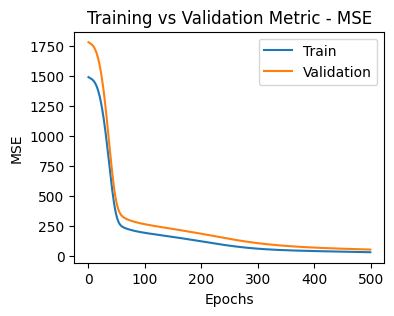

In [20]:
plt.figure(figsize=(4, 3))
plt.plot(train_mses, label='Train')
plt.plot(test_mses, label='Validation')
plt.legend(loc='best')
plt.xlabel('Epochs')
plt.ylabel('MSE')
plt.title('Training vs Validation Metric - MSE')
plt.show()

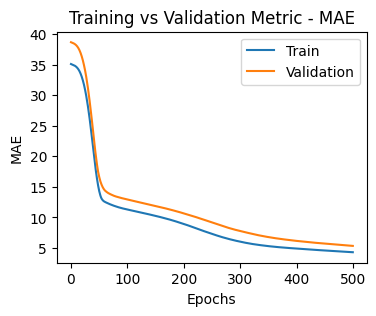

In [21]:
plt.figure(figsize=(4, 3))
plt.plot(train_maes, label='Train')
plt.plot(test_maes, label='Validation')
plt.legend(loc='best')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.title('Training vs Validation Metric - MAE')
plt.show()

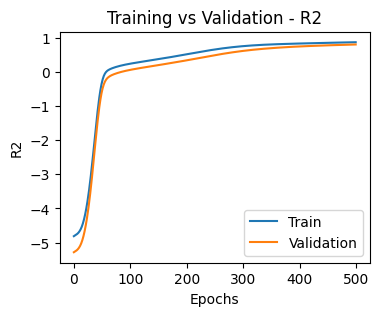

In [22]:
plt.figure(figsize=(4, 3))
plt.plot(train_r2s, label='Train')
plt.plot(test_r2s, label='Validation')
plt.legend(loc='best')
plt.xlabel('Epochs')
plt.ylabel('R2')
plt.title('Training vs Validation - R2')
plt.show()

ВИСНОВКИ

У ході виконання роботи було розроблено модель глибокого навчання для прогнозування міцності бетону на основі його складових компонентів та інших факторів. Показники ефективності свідчать про високу ефективність моделі: MSE: 32.4142, MAE: 4.2930, R2: 0.8736. Алгоритм Adam та підібрані гіперпарметри чудово підходять для даної задачі.